In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.svm import SVC

In [2]:
data = fetch_california_housing()
df = pd.DataFrame(data.data, columns=data.feature_names)
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [3]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [4]:
#4. Standardiser les données.
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)
print(pd.DataFrame(df_scaled, columns=data.feature_names).head())

     MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  2.344766  0.982143  0.628559  -0.153758   -0.974429 -0.049597  1.052548   
1  2.332238 -0.607019  0.327041  -0.263336    0.861439 -0.092512  1.043185   
2  1.782699  1.856182  1.155620  -0.049016   -0.820777 -0.025843  1.038503   
3  0.932968  1.856182  0.156966  -0.049833   -0.766028 -0.050329  1.038503   
4 -0.012881  1.856182  0.344711  -0.032906   -0.759847 -0.085616  1.038503   

   Longitude  
0  -1.327835  
1  -1.322844  
2  -1.332827  
3  -1.337818  
4  -1.337818  


In [5]:
#5. Appliquer DBSCAN avec 𝜀 = 0.5 et min_samples=10.
dbscan = DBSCAN(eps=0.5, min_samples=10)

# Entrainer DBSCAN et recuperer les labels
labels = dbscan.fit_predict(df_scaled)

# Ajouter les labels au DataFrame original
df["Cluster"] = labels


# 4. Count points in each cluster, including noise (-1)
print("Nombre de points dans chaque cluster :")
print(df["Cluster"].value_counts().sort_index())

Nombre de points dans chaque cluster :
Cluster
-1     4281
 0    16233
 1       49
 2       24
 3       20
 4       10
 5       13
 6       10
Name: count, dtype: int64


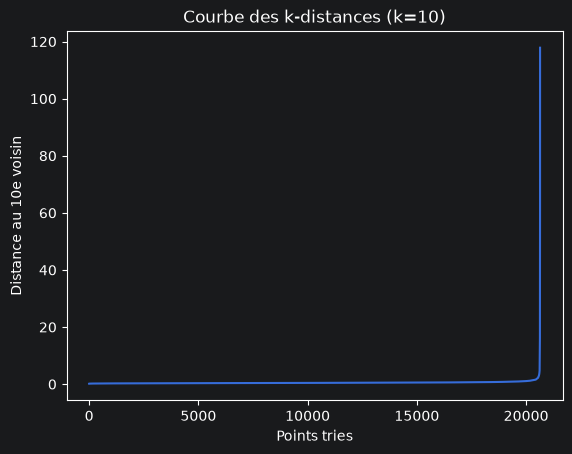

In [6]:
#6. Écrire une fonction pour tracer la courbe des k-distances.
from sklearn.neighbors import NearestNeighbors

def courbe_k_distance(X, k=10):
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)
    distances = np.sort(distances[:, -1])
    plt.plot(distances)
    plt.title(f"Courbe des k-distances (k={k})")
    plt.xlabel("Points tries")
    plt.ylabel(f"Distance au {k}e voisin")
    plt.show()

courbe_k_distance(df_scaled, k=10)

In [7]:
#7. Tester plusieurs valeurs de min_samples
for min_samples in [5, 10, 20]:
  dbscan = DBSCAN(eps=0.5, min_samples=min_samples)
  labels = dbscan.fit_predict(df_scaled)
  # Calculer le nombre de clusters
  # Attention : le label -1 correspond au bruit
  n_clusters = len(set(labels) - {-1})

  print(f"min_samples={min_samples} : Nombre de clusters = {n_clusters}")

min_samples=5 : Nombre de clusters = 25
min_samples=10 : Nombre de clusters = 7
min_samples=20 : Nombre de clusters = 3


<Figure size 1000x600 with 0 Axes>

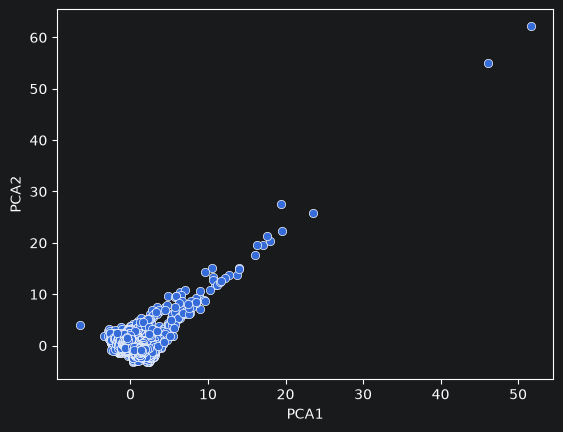

<Figure size 1000x600 with 0 Axes>

In [8]:
#Réduire la dimension du dataset avec PCA.
pca = PCA(n_components=2)
# Appliquer PCA aux donnees standardisees
df_pca = pca.fit_transform(df_scaled)

# Ajouter les deux composantes au DataFrame
df["PCA1"] = df_pca[:, 0]
df["PCA2"] = df_pca[:, 1]

sns.scatterplot(x=df["PCA1"], y=df["PCA2"])

plt.figure(figsize=(10, 6))


In [16]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

results = []

for eps in np.arange(0.1, 1.1, 0.1):
    for min_samples in [3, 5, 10, 15]:

        model = DBSCAN(
            eps=round(eps, 2),
            min_samples=min_samples
        )

        labels = model.fit_predict(df_pca)

        # Exclude noise points
        mask = labels != -1
        X_eval = df_pca[mask]
        labels_eval = labels[mask]

        n_clusters = len(set(labels_eval))
        noise_ratio = np.mean(labels == -1)

        # Silhouette requires at least 2 clusters
        if 2 <= n_clusters < len(X_eval):
            score = silhouette_score(X_eval, labels_eval)
        else:
            score = np.nan

        results.append({
            "eps": round(eps, 2),
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "noise_ratio": round(noise_ratio, 3),
            "silhouette": score
        })

results_df = pd.DataFrame(results)

print(
    results_df.sort_values(
        "silhouette",
        ascending=False,
        na_position="last"
    ).head(10)
)

    eps  min_samples  n_clusters  noise_ratio  silhouette
33  0.9            5           2        0.002    0.832327
32  0.9            3           3        0.001    0.832177
37  1.0            5           3        0.001    0.830005
36  1.0            3           3        0.001    0.829882
28  0.8            3           3        0.001    0.828747
24  0.7            3           4        0.001    0.823830
21  0.6            5           4        0.003    0.768942
25  0.7            5           3        0.002    0.766285
34  0.9           10           4        0.002    0.766240
22  0.6           10           2        0.006    0.717368


In [9]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import silhouette_score

# Custom scoring function
def dbscan_silhouette(estimator, X):
    labels = estimator.fit_predict(X)

    # Exclude noise points
    mask = labels != -1
    X_clean = X[mask]
    labels_clean = labels[mask]

    n_clusters = len(set(labels_clean))

    # Silhouette requires at least 2 clusters
    if n_clusters < 2 or n_clusters >= len(X_clean):
        return -1

    return silhouette_score(X_clean, labels_clean)


# Hyperparameters to test
params = {
    "eps": np.arange(0.1, 1.1, 0.1),
    "min_samples": [3, 5, 10, 15]
}

dbscan = DBSCAN()

# One split: evaluate each combination on the entire dataset
grid = GridSearchCV(
    estimator=dbscan,
    param_grid=params,
    scoring=dbscan_silhouette,
    cv=[(np.arange(len(df_pca)), np.arange(len(df_pca)))],
    n_jobs=2
)

grid.fit(df_pca)

print("Best parameters:", grid.best_params_)
print("Best silhouette score:", grid.best_score_)

Best parameters: {'eps': np.float64(0.9), 'min_samples': 5}
Best silhouette score: 0.8323269281965541
